# First Model Exploration: pedestrian trajectory prediction (LSTM)
**Project:** Predictive Navigation for Mobile Robots in Pedestrian Environments
**Homework:** First Model Exploration (preparation for Milestone 4, Section 7)

**Notebook contents:**
1. Role of AI and candidates
2. Setup
3. Data: load, inspect, split
4. Preparing the examples
5. Baselines (no learning)
6. Run 1: first LSTM (simplest working configuration)
7. Evaluation of run 1
8. Error inspection and practical constraints
9. Run 2: one targeted change
10. Experiment table and summary

Everything is computed from the simulator dataset (`trajectories/peds_0_499.csv`, made with `make_data.py`).
The **test split is never used** in this notebook.

> **Note on scope:** this is a **first training sample**, a short exploratory run to get the AI component working end to end and see early results. The LSTM is **not yet integrated** into the car's driving loop: the car currently drives with the constant-velocity (predictive) and reactive brains. Plugging the trained LSTM in as the `lstm` brain and testing it in the simulator is the next step (Milestone 4).

## 1. Role of AI and candidate approaches

**What the AI does.** The AI component *predicts where each pedestrian will be* over the next 3.2 s.
- **Input:** the pedestrian's recent track, i.e. their last positions (x, y) every 0.4 s.
- **Output:** their next 8 positions (0.4 s … 3.2 s ahead).

The car's planner uses these predicted positions to choose a safe path (keep going, slow down, swerve or stop).

**Candidates considered**

| Candidate | Type | Notes |
|---|---|---|
| Stay-put (reactive brain) | no learning | assumes the person does not move; the "reactive" baseline |
| Constant velocity (predictive brain) | no learning | keeps the last observed velocity; what the car uses today |
| **LSTM encoder → linear decoder** | learned | **explored first**: small, made for short sequences, trains in minutes on a laptop |
| Transformer | learned | possible later; needs more data and tuning |
| YOLO (detection stage) | learned | a different stage of the pipeline (finding people in camera images); comes after this |

**Why the LSTM first:** the inputs are short, regular sequences (one point every 0.4 s), and the
dataset is large (over 10,000 tracks). A one-layer LSTM is the simplest learned sequence model that can
pick up stopping, turning and waiting at the kerb, which constant velocity cannot. It trains on a laptop
CPU or GPU in a few minutes.

**Parts of the system that are not AI:**
- the simulator itself;
- perception geometry (the camera cone, people hidden behind objects);
- the planner (candidate paths, cost terms, safety margins);
- traffic rules (red lights, zebra crossings, waiting to turn left);
- the evaluation metrics.

These are tested separately with `evaluate.py` (reactive vs predictive brain in closed loop).

**Stage explored first:** prediction, because the planner's decisions depend directly on it, and the
dataset for it is ready. Detection (YOLO) is the next stage.

**External models and services:** none. No pretrained model, no API. The only libraries are PyTorch
(BSD licence), NumPy, pandas and Matplotlib. All data comes from our own simulator.

## 2. Setup

In [1]:
import time, math, os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA_PATH = "trajectories/peds_0_499.csv"     # made with: python make_data.py --episodes 500
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

DT = 0.4          # s between points (fixed by the dataset)
OBS_MAX = 12      # history kept in every example (run 2 uses all 12, run 1 the last 8)
PRED = 8          # predicted points: 8 x 0.4 s = 3.2 s ahead
STRIDE_TRAIN = 2  # start a new training example every 2 points (0.8 s)
STRIDE_VAL = 4    # validation examples every 4 points (1.6 s)
MAX_TRAIN = 200_000   # cap on training examples (modest budget)
LATENCY_TARGET_MS = 100.0   # latency target from Section 2.1 (here: the car's 0.1 s control step - change if yours differs)

device = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))
print("torch", torch.__version__, "| device:", device)

torch 2.14.0 | device: mps


## 3. Data: load, inspect, split

**Dataset version:**
- **Source:** `trajectories/peds_0_499.csv` from `make_data.py`.
- **Size:** 500 simulator runs of 60 s, half town and half street. In 150 runs the robot car drives through with the predictive brain.
- **Split (Section 6.5):** by run (seed), with whole runs kept in one split: train / val / test = 14 / 3 / 3 out of every 20 seeds. So no track, and no near-identical frame, appears in two splits.

In [2]:
df = pd.read_csv(DATA_PATH)
print("rows:", len(df), "| columns:", list(df.columns))
print("\nmissing values per column:\n", df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "none")

df = df.sort_values(["episode", "ped_id", "t"]).reset_index(drop=True)
g = df.groupby(["episode", "ped_id"])
gaps = g["t"].diff().dropna().round(2)
steps = np.hypot(g["x"].diff(), g["y"].diff()).dropna()
print("\ntime between points:", gaps.value_counts().to_dict())
print("largest jump between two points: %.2f m (walking at most ~1.1 m per 0.4 s)" % steps.max())

runs = df.groupby("episode")["split"].first()
tracks = df.groupby(["episode", "ped_id"]).agg(split=("split", "first"), n=("t", "size"), layout=("layout", "first"))
print("\nruns per split:", runs.value_counts().to_dict())
print("tracks per split:", tracks["split"].value_counts().to_dict())
print("points per track: min %d, mean %.0f, max %d" % (tracks.n.min(), tracks.n.mean(), tracks.n.max()))
print("\nwhat people are doing (share of points):", df["mode"].value_counts(normalize=True).round(3).to_dict())
print("share of points on the road: %.3f" % df["on_road"].mean())

rows: 1526125 | columns: ['episode', 'split', 'layout', 't', 'ped_id', 'group_id', 'kind', 'x', 'y', 'vx', 'vy', 'mode', 'on_road']

missing values per column:
 none

time between points: {0.4: 1515670}
largest jump between two points: 1.12 m (walking at most ~1.1 m per 0.4 s)

runs per split: {'train': 350, 'val': 75, 'test': 75}
tracks per split: {'train': 7380, 'val': 1741, 'test': 1334}
points per track: min 78, mean 146, max 151

what people are doing (share of points): {'walk': 0.6, 'pause': 0.155, 'cross': 0.138, 'wait': 0.107}
share of points on the road: 0.129


**Data handling:**
- **Filled:** nothing (no missing values).
- **Dropped:** nothing at this stage (no time gaps, no jumps).
- **Left unchanged:** all positions. The only learned preprocessing is a scale for the inputs, fitted on the **training split only** (section 4).

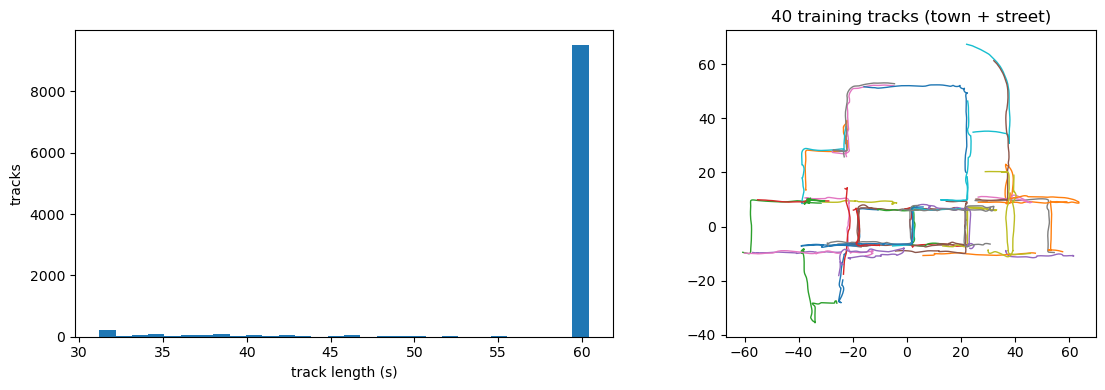

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(tracks.n * DT, bins=30); ax[0].set_xlabel("track length (s)"); ax[0].set_ylabel("tracks")
sample = tracks[tracks.split == "train"].sample(40, random_state=SEED).index
for key in sample:
    tr = df[(df.episode == key[0]) & (df.ped_id == key[1])]
    ax[1].plot(tr.x, tr.y, lw=1)
ax[1].set_aspect("equal"); ax[1].set_title("40 training tracks (town + street)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/data_overview.png", dpi=110); plt.show()

## 4. Preparing the examples

Each example is a window of 20 consecutive points from one track:
- **History:** 12 points, 4.4 s. Run 1 uses only the last 8 of them (2.8 s).
- **Future:** the next 8 points (3.2 s).

The **same examples** are used to evaluate every method, so the comparison is fair.

**What the model sees:**
- **Inputs:** the steps between consecutive history points (dx, dy). Only relative motion, so the model can't memorise places in the map.
- **Outputs:** the future positions relative to the last seen point.
- **Scaling:** one scale for the inputs, from the standard deviation of the steps, computed on the **training split only**.

In [4]:
WIN = OBS_MAX + PRED

def make_windows(split, stride):
    xs, info = [], []
    part = df[df.split == split]
    for (ep, pid), tr in part.groupby(["episode", "ped_id"], sort=False):
        xy = tr[["x", "y"]].to_numpy(np.float32)
        if len(xy) < WIN:
            continue
        mode, road, layout = tr["mode"].to_numpy(), tr["on_road"].to_numpy(), tr["layout"].iloc[0]
        for s in range(0, len(xy) - WIN + 1, stride):
            xs.append(xy[s:s + WIN])
            last = s + OBS_MAX - 1
            info.append((ep, pid, layout, mode[last], mode[s + WIN - 1], int(road[last]),
                         int(road[s + OBS_MAX:s + WIN].max())))
    info = pd.DataFrame(info, columns=["episode", "ped_id", "layout", "mode_now", "mode_end",
                                       "on_road_now", "on_road_future"])
    return np.stack(xs), info

t0 = time.time()
W_train, I_train = make_windows("train", STRIDE_TRAIN)
W_val, I_val = make_windows("val", STRIDE_VAL)
if len(W_train) > MAX_TRAIN:                      # modest training budget: a random subset
    keep = np.random.default_rng(SEED).choice(len(W_train), MAX_TRAIN, replace=False)
    W_train, I_train = W_train[keep], I_train.iloc[keep].reset_index(drop=True)
print(f"training examples: {len(W_train):,}   validation examples: {len(W_val):,}   ({time.time() - t0:.0f} s)")

def split_window(W, obs):
    hist = W[:, OBS_MAX - obs:OBS_MAX]                  # (N, obs, 2) last `obs` history points
    last = W[:, OBS_MAX - 1:OBS_MAX]                    # (N, 1, 2)
    fut = W[:, OBS_MAX:] - last                         # (N, PRED, 2) future, relative to last point
    steps = np.diff(hist, axis=1)                       # (N, obs-1, 2) model input
    return steps, fut, hist - last

SCALE = float(np.diff(W_train[:, :OBS_MAX], axis=1).std())    # fitted on training data only
print("input scale (std of a 0.4 s step, train only): %.3f m" % SCALE)
print("validation examples by what the person is doing at the last seen point:")
print(I_val["mode_now"].value_counts().to_dict())

training examples: 200,000   validation examples: 56,021   (2 s)
input scale (std of a 0.4 s step, train only): 0.303 m
validation examples by what the person is doing at the last seen point:
{'walk': 33115, 'pause': 8419, 'cross': 7938, 'wait': 6549}


**Leakage check** (before trusting any score):
1. No run (seed) appears in both training and validation.
2. The inputs are only *past* steps; the future points are never part of the input.
3. The only learned preprocessing (the scale) was fitted on training data only.
4. The test split is not loaded into any example set.

In [5]:
overlap = set(I_train.episode) & set(I_val.episode)
test_runs = set(runs[runs == "test"].index)
print("runs in both train and validation:", len(overlap))
print("test runs used in train or validation:", len((set(I_train.episode) | set(I_val.episode)) & test_runs))
steps_chk, fut_chk, _ = split_window(W_val[:5], 8)
print("input uses points", OBS_MAX - 8, "to", OBS_MAX - 1, "| targets are points", OBS_MAX, "to", OBS_MAX + PRED - 1,
      "-> no overlap between input and target")
assert not overlap and not ((set(I_train.episode) | set(I_val.episode)) & test_runs)

runs in both train and validation: 0
test runs used in train or validation: 0
input uses points 4 to 11 | targets are points 12 to 19 -> no overlap between input and target


## 5. Baselines (no learning)

**Metrics:**
- **ADE (Average Displacement Error):** the mean distance in metres between predicted and true positions over the 8 future points.
- **FDE (Final Displacement Error):** the same, only at 3.2 s ahead.

These measure exactly what the planner needs: how far off "where will this person be" is. Lower is better.

In [6]:
def ade_fde(pred, fut):
    err = np.linalg.norm(pred - fut, axis=2)            # (N, PRED)
    return float(err.mean()), float(err[:, -1].mean()), err

_, FUT_val, _ = split_window(W_val, OBS_MAX)
k = np.arange(1, PRED + 1, dtype=np.float32)[None, :, None]

pred_stay = np.zeros_like(FUT_val)                                     # stays where they are
last_step = (W_val[:, OBS_MAX - 1] - W_val[:, OBS_MAX - 2])[:, None, :]
pred_cv = last_step * k                                                # keeps the last velocity

results = []
for name, pred in [("Stay-put (reactive brain)", pred_stay), ("Constant velocity (predictive brain)", pred_cv)]:
    ade, fde, _ = ade_fde(pred, FUT_val)
    results.append({"run": name, "config": "no learning", "change": "-", "ADE_m": ade, "FDE_m": fde,
                    "val_examples": len(FUT_val), "train_time_s": 0.0})
    print(f"{name:40s} ADE {ade:.3f} m   FDE {fde:.3f} m   on {len(FUT_val):,} validation examples")

Stay-put (reactive brain)                ADE 1.599 m   FDE 2.793 m   on 56,021 validation examples
Constant velocity (predictive brain)     ADE 0.583 m   FDE 1.236 m   on 56,021 validation examples


## 6. Run 1: first LSTM, simplest working configuration

**Model:**
- One-layer LSTM over the history steps, hidden size 64.
- A linear layer turns the last hidden state into the 8 future steps.
- The steps are added up into positions.

**Training:**
- Loss: mean squared error on the future positions.
- Adam, learning rate 1e-3, batch 512, 5 epochs.
- Seed 0.

Everything is recorded in the config dictionary.

In [7]:
class LSTMPredictor(nn.Module):
    def __init__(self, hidden=64, pred=PRED):
        super().__init__()
        self.lstm = nn.LSTM(input_size=2, hidden_size=hidden, num_layers=1, batch_first=True)
        self.head = nn.Linear(hidden, pred * 2)
        self.pred = pred

    def forward(self, steps):                         # steps: (B, obs-1, 2), scaled
        _, (h, _) = self.lstm(steps)
        out = self.head(h[-1]).view(-1, self.pred, 2)  # predicted future steps (scaled)
        return torch.cumsum(out, dim=1) * SCALE        # -> positions relative to last point (m)


def train_run(cfg):
    torch.manual_seed(cfg["seed"]); np.random.seed(cfg["seed"])
    xs_tr, y_tr, _ = split_window(W_train, cfg["obs"])
    xs_va, y_va, _ = split_window(W_val, cfg["obs"])
    Xtr = torch.tensor(xs_tr / SCALE); Ytr = torch.tensor(y_tr)
    Xva = torch.tensor(xs_va / SCALE).to(device); Yva = torch.tensor(y_va).to(device)
    model = LSTMPredictor(cfg["hidden"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    history = {"train_loss": [], "val_loss": []}
    t0 = time.time()
    for epoch in range(cfg["epochs"]):
        model.train()
        perm = torch.randperm(len(Xtr))
        total = 0.0
        for i in range(0, len(Xtr), cfg["batch"]):
            idx = perm[i:i + cfg["batch"]]
            xb, yb = Xtr[idx].to(device), Ytr[idx].to(device)
            loss = ((model(xb) - yb) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val = float(np.mean([((model(Xva[j:j + 4096]) - Yva[j:j + 4096]) ** 2).mean().item()
                                 for j in range(0, len(Xva), 4096)]))
        history["train_loss"].append(total / len(Xtr)); history["val_loss"].append(val)
        print(f"  epoch {epoch + 1}/{cfg['epochs']}: train loss {history['train_loss'][-1]:.4f}  val loss {val:.4f}")
    train_time = time.time() - t0
    with torch.no_grad():
        pred = np.concatenate([model(Xva[j:j + 4096]).cpu().numpy() for j in range(0, len(Xva), 4096)])
    return model, pred, history, train_time


cfg1 = {"name": "LSTM run 1", "obs": 8, "hidden": 64, "lr": 1e-3, "batch": 512, "epochs": 5, "seed": SEED,
        "train_examples": len(W_train), "data": DATA_PATH + " (train split)", "torch": torch.__version__,
        "device": str(device)}
print("config:", json.dumps(cfg1, indent=1))
model1, pred1, hist1, time1 = train_run(cfg1)
ade1, fde1, err1 = ade_fde(pred1, FUT_val)
n_params = sum(p.numel() for p in model1.parameters())
def cfg_text(c):
    return f"LSTM 1 layer, hidden {c['hidden']}, history {c['obs']} pts, lr {c['lr']}, batch {c['batch']}, {c['epochs']} epochs, seed {c['seed']}"
results.append({"run": "LSTM run 1", "config": cfg_text(cfg1), "change": "first configuration (history 8 points = 2.8 s)",
                "ADE_m": ade1, "FDE_m": fde1, "val_examples": len(FUT_val), "train_time_s": time1})
print(f"\nLSTM run 1: ADE {ade1:.3f} m  FDE {fde1:.3f} m  |  {n_params:,} parameters  |  trained in {time1:.0f} s")

config: {
 "name": "LSTM run 1",
 "obs": 8,
 "hidden": 64,
 "lr": 0.001,
 "batch": 512,
 "epochs": 5,
 "seed": 0,
 "train_examples": 200000,
 "data": "trajectories/peds_0_499.csv (train split)",
 "torch": "2.14.0",
 "device": "mps"
}
  epoch 1/5: train loss 0.6910  val loss 0.4454
  epoch 2/5: train loss 0.4406  val loss 0.4152
  epoch 3/5: train loss 0.4285  val loss 0.4123
  epoch 4/5: train loss 0.4245  val loss 0.4104
  epoch 5/5: train loss 0.4213  val loss 0.4079

LSTM run 1: ADE 0.566 m  FDE 1.205 m  |  18,448 parameters  |  trained in 4 s


## 7. Evaluation of run 1 (validation split)
These results are **preliminary**: one short training run (5 epochs on a 200,000-example subset) with a single seed.

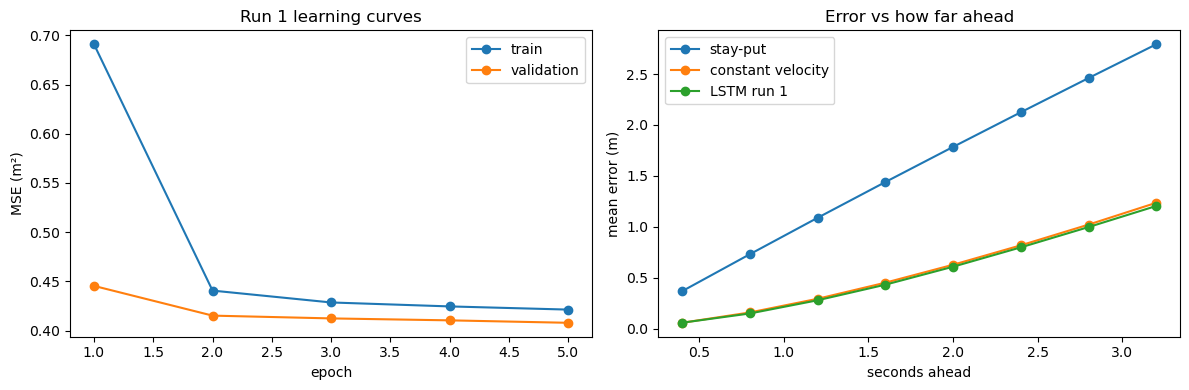

,doing (last seen),examples,ADE stay-put,ADE const. vel.,ADE LSTM run 1
0,walk,33115,1.944,0.599,0.588
1,cross,7938,2.341,0.493,0.551
2,wait,6549,0.279,0.345,0.335
3,pause,8419,0.568,0.789,0.671


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(hist1["train_loss"]) + 1), hist1["train_loss"], "o-", label="train")
ax[0].plot(range(1, len(hist1["val_loss"]) + 1), hist1["val_loss"], "o-", label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE (m²)"); ax[0].set_title("Run 1 learning curves"); ax[0].legend()
_, _, e_stay = ade_fde(pred_stay, FUT_val); _, _, e_cv = ade_fde(pred_cv, FUT_val)
t_ahead = np.arange(1, PRED + 1) * DT
for e, name in [(e_stay, "stay-put"), (e_cv, "constant velocity"), (err1, "LSTM run 1")]:
    ax[1].plot(t_ahead, e.mean(axis=0), "o-", label=name)
ax[1].set_xlabel("seconds ahead"); ax[1].set_ylabel("mean error (m)"); ax[1].set_title("Error vs how far ahead")
ax[1].legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/run1_curves.png", dpi=110); plt.show()

# where does each method do well or badly? (by what the person is doing at the last seen point)
rows = []
for m in ["walk", "cross", "wait", "pause"]:
    sel = (I_val.mode_now == m).to_numpy()
    if sel.sum():
        rows.append({"doing (last seen)": m, "examples": int(sel.sum()),
                     "ADE stay-put": e_stay[sel].mean(), "ADE const. vel.": e_cv[sel].mean(),
                     "ADE LSTM run 1": err1[sel].mean()})
by_mode = pd.DataFrame(rows).round(3)
by_mode

## 8. Error inspection and practical constraints

**Worst cases:** the 8 validation examples where run 1's final error (3.2 s ahead) is largest.
For each one we show what the person was doing when last seen and at the end, and whether they were on the road.
The model does not output a confidence score, so "confidently wrong" predictions can't be identified; instead we look
at the largest errors directly.

,layout,mode_now,mode_end,on_road_now,on_road_future,speed_now_mps,FDE_LSTM_m,FDE_constvel_m
0,town,wait,cross,0,1,1.66,8.37,9.64
1,town,cross,wait,1,1,1.90,8.02,9.47
2,town,cross,wait,1,1,2.17,7.72,9.36
3,town,cross,cross,1,1,0.34,7.66,5.70
4,town,walk,pause,1,1,1.96,7.64,9.26
5,town,cross,pause,1,1,2.00,7.49,8.84
6,town,cross,pause,1,1,1.70,7.21,8.53
7,town,cross,wait,1,1,1.88,7.09,8.25


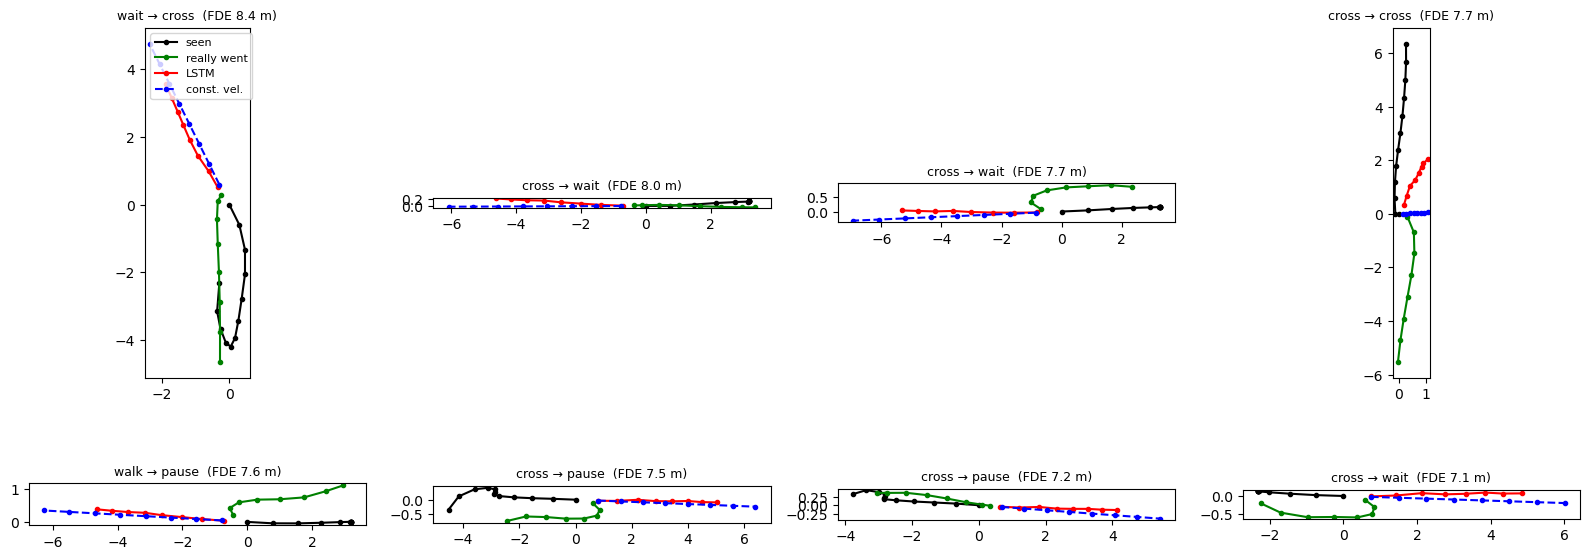

worst 5% of validation examples: 2,801 cases. What they have in common:


,the person ...,share of worst 5%,share of all examples,how much more common
0,changed what they were doing (e.g. walking -> ...,0.54,0.31,1.75
1,were on the road at some point in the next 3.2 s,0.29,0.18,1.62
2,were standing or pausing when last seen,0.34,0.27,1.27
3,were moving fast (over 1.6 m/s),0.07,0.06,1.07


-> most typical of the bad cases: people who changed what they were doing (e.g. walking -> waiting at the kerb, waiting -> crossing) (54% of the worst cases vs 31% of all examples)


In [9]:
fde_each = err1[:, -1]
worst = np.argsort(-fde_each)[:8]
table = I_val.iloc[worst][["layout", "mode_now", "mode_end", "on_road_now", "on_road_future"]].copy()
speed_now = np.linalg.norm(W_val[worst, OBS_MAX - 1] - W_val[worst, OBS_MAX - 2], axis=1) / DT
table["speed_now_mps"] = speed_now.round(2)
table["FDE_LSTM_m"] = fde_each[worst].round(2)
table["FDE_constvel_m"] = e_cv[worst, -1].round(2)
display(table.reset_index(drop=True))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for a, i in zip(axes.ravel(), worst):
    hist = W_val[i, :OBS_MAX] - W_val[i, OBS_MAX - 1]
    a.plot(hist[:, 0], hist[:, 1], "k.-", label="seen")
    a.plot(FUT_val[i, :, 0], FUT_val[i, :, 1], "g.-", label="really went")
    a.plot(pred1[i, :, 0], pred1[i, :, 1], "r.-", label="LSTM")
    a.plot(pred_cv[i, :, 0], pred_cv[i, :, 1], "b.--", label="const. vel.")
    a.set_title(f"{I_val.mode_now.iloc[i]} → {I_val.mode_end.iloc[i]}  (FDE {fde_each[i]:.1f} m)", fontsize=9)
    a.set_aspect("equal")
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/run1_worst_cases.png", dpi=110); plt.show()

# what do bad cases have in common? (worst 5% of examples vs all examples)
def common_factors(err_final):
    bad = err_final > np.quantile(err_final, 0.95)
    speed = np.linalg.norm(W_val[:, OBS_MAX - 1] - W_val[:, OBS_MAX - 2], axis=1) / DT
    factors = {
        "changed what they were doing (e.g. walking -> waiting at the kerb, waiting -> crossing)":
            (I_val.mode_now != I_val.mode_end).to_numpy(),
        "were on the road at some point in the next 3.2 s": I_val.on_road_future.to_numpy() == 1,
        "were moving fast (over 1.6 m/s)": speed > 1.6,
        "were standing or pausing when last seen": I_val.mode_now.isin(["wait", "pause"]).to_numpy(),
    }
    rows = [{"the person ...": k, "share of worst 5%": v[bad].mean(), "share of all examples": v.mean(),
             "how much more common": v[bad].mean() / max(v.mean(), 1e-9)} for k, v in factors.items()]
    return pd.DataFrame(rows).sort_values("how much more common", ascending=False).reset_index(drop=True), bad.sum()

factors1, n_bad = common_factors(fde_each)
print(f"worst 5% of validation examples: {n_bad:,} cases. What they have in common:")
display(factors1.round(2))
top1 = factors1.iloc[0]
print(f"-> most typical of the bad cases: people who {top1['the person ...']} "
      f"({top1['share of worst 5%']:.0%} of the worst cases vs {top1['share of all examples']:.0%} of all examples)")

**Practical constraint: inference time.**
- The car re-plans every **0.1 s**, and the prediction for every person in view must fit inside that step together with the planner.
- We time one forward pass for 1 person and for 30 people (a busy street) on the CPU.
- Compare these numbers with the latency target in Section 2.1 of the project template.

In [10]:
cpu_model = LSTMPredictor(cfg1["hidden"]); cpu_model.load_state_dict({k: v.cpu() for k, v in model1.state_dict().items()})
cpu_model.eval()
def latency_ms(model, n_people, obs, reps=200):
    x = torch.randn(n_people, obs - 1, 2)
    with torch.no_grad():
        for _ in range(10): model(x)
        t0 = time.perf_counter()
        for _ in range(reps): model(x)
    return (time.perf_counter() - t0) / reps * 1000
lat1_1, lat1_30 = latency_ms(cpu_model, 1, cfg1["obs"]), latency_ms(cpu_model, 30, cfg1["obs"])
size_kb = n_params * 4 / 1024
print(f"run 1 on CPU: {lat1_1:.2f} ms for 1 person, {lat1_30:.2f} ms for 30 people "
      f"(target from Section 2.1: {LATENCY_TARGET_MS:.0f} ms) -> {'meets' if lat1_30 < LATENCY_TARGET_MS else 'MISSES'} the target"
      f" | model size {size_kb:.0f} KB ({n_params:,} parameters) | measured on: {os.uname().machine} CPU, batch of 30, average of 200 runs")
results[-1]["infer_ms_30_people"] = lat1_30

run 1 on CPU: 0.07 ms for 1 person, 0.22 ms for 30 people (target from Section 2.1: 100 ms) -> meets the target | model size 72 KB (18,448 parameters) | measured on: arm64 CPU, batch of 30, average of 200 runs


## 9. Run 2: one targeted change

**Change:** a longer history, **12 points (4.4 s) instead of 8 (2.8 s)**. Everything else stays the same: model size, learning rate, epochs, seed, training examples and validation examples.

**Why:**
- The hardest moments to predict are when a person *changes* what they are doing, such as slowing down to stop at the kerb, starting to cross, or pausing. Section 8 shows which kinds of cases dominate the errors.
- A longer history shows *how* the person was moving before (for example slowing down as they reach the kerb), which should help the model anticipate the change.

**Expected effect:** lower FDE (the error 3.2 s ahead), with little change in ADE.

In [11]:
cfg2 = dict(cfg1, name="LSTM run 2", obs=12)
print("config:", json.dumps(cfg2, indent=1))
model2, pred2, hist2, time2 = train_run(cfg2)
ade2, fde2, err2 = ade_fde(pred2, FUT_val)
cpu2 = LSTMPredictor(cfg2["hidden"]); cpu2.load_state_dict({k: v.cpu() for k, v in model2.state_dict().items()}); cpu2.eval()
lat2_30 = latency_ms(cpu2, 30, cfg2["obs"])
results.append({"run": "LSTM run 2", "config": cfg_text(cfg2), "change": "longer history: 12 points (4.4 s) instead of 8",
                "ADE_m": ade2, "FDE_m": fde2, "val_examples": len(FUT_val), "train_time_s": time2,
                "infer_ms_30_people": lat2_30})
print(f"\nLSTM run 2: ADE {ade2:.3f} m  FDE {fde2:.3f} m  (run 1: ADE {ade1:.3f}  FDE {fde1:.3f})  "
      f"| trained in {time2:.0f} s | {lat2_30:.2f} ms for 30 people")

changed = (I_val.mode_now != I_val.mode_end).to_numpy()
print(f"FDE on examples where the person changes what they are doing: run 1 {err1[changed, -1].mean():.3f} m, "
      f"run 2 {err2[changed, -1].mean():.3f} m  ({changed.sum():,} examples)")

config: {
 "name": "LSTM run 2",
 "obs": 12,
 "hidden": 64,
 "lr": 0.001,
 "batch": 512,
 "epochs": 5,
 "seed": 0,
 "train_examples": 200000,
 "data": "trajectories/peds_0_499.csv (train split)",
 "torch": "2.14.0",
 "device": "mps"
}
  epoch 1/5: train loss 0.6808  val loss 0.4433
  epoch 2/5: train loss 0.4388  val loss 0.4147
  epoch 3/5: train loss 0.4269  val loss 0.4100
  epoch 4/5: train loss 0.4212  val loss 0.4071
  epoch 5/5: train loss 0.4166  val loss 0.4044

LSTM run 2: ADE 0.567 m  FDE 1.205 m  (run 1: ADE 0.566  FDE 1.205)  | trained in 5 s | 0.31 ms for 30 people
FDE on examples where the person changes what they are doing: run 1 1.610 m, run 2 1.603 m  (17,181 examples)


## 10. Experiment table and summary

In [12]:
table = pd.DataFrame(results)
table["infer_ms_30_people"] = table.get("infer_ms_30_people", np.nan)
table = table[["run", "config", "change", "ADE_m", "FDE_m", "val_examples", "train_time_s", "infer_ms_30_people"]]
table.to_csv(f"{OUT_DIR}/experiments.csv", index=False)
display(table.round(3))

,run,config,change,ADE_m,FDE_m,val_examples,train_time_s,infer_ms_30_people
0,Stay-put (reactive brain),no learning,-,1.599,2.793,56021,0.000,NaN
1,Constant velocity (predictive brain),no learning,-,0.583,1.236,56021,0.000,NaN
2,LSTM run 1,"LSTM 1 layer, hidden 64, history 8 pts, lr 0.0...",first configuration (history 8 points = 2.8 s),0.566,1.205,56021,4.302,0.216
3,LSTM run 2,"LSTM 1 layer, hidden 64, history 12 pts, lr 0....",longer history: 12 points (4.4 s) instead of 8,0.567,1.205,56021,4.859,0.313


> **Scope reminder:** this is a **first training sample**, a short exploratory run to get the AI component working end to end and see early results. The LSTM is **not yet integrated** into the car's driving loop: the car currently drives with the constant-velocity (predictive) and reactive brains. Plugging the trained LSTM in as the `lstm` brain and testing it in the simulator is the next step (Milestone 4).

In [13]:
best_cv = results[1]
d_ade, d_fde = ade2 - ade1, fde2 - fde1
effect = ("helped" if d_fde < -0.01 else "hurt" if d_fde > 0.01 else "made no clear difference")
note = f'''SUMMARY NOTE (numbers from this run)
- Scope: this is a first training sample (a short exploratory run). The LSTM is not yet integrated into the
  car's driving loop - the car still drives with the constant-velocity and reactive brains; plugging it in is next.
- Selected candidate: a one-layer LSTM (hidden 64) that predicts a pedestrian's next 8 positions (3.2 s) from their recent
  track; first stage explored = prediction, because the car's planner depends on it (detection with YOLO comes next).
- Initial result (run 1, history 2.8 s, 5 epochs, {len(W_train):,} training examples, {len(FUT_val):,} validation examples):
  ADE {ade1:.3f} m, FDE {fde1:.3f} m, vs constant velocity ADE {best_cv["ADE_m"]:.3f} m, FDE {best_cv["FDE_m"]:.3f} m
  and stay-put ADE {results[0]["ADE_m"]:.3f} m, FDE {results[0]["FDE_m"]:.3f} m.
- Observed failure: the largest errors (worst 5%) are most typical of people who {top1['the person ...']}:
  {top1['share of worst 5%']:.0%} of the worst cases vs {top1['share of all examples']:.0%} of all examples.
- Practical constraint: {lat1_30:.2f} ms on CPU for 30 people at once (target {LATENCY_TARGET_MS:.0f} ms) - well within it.
- Targeted change (run 2): longer history, 12 points (4.4 s) instead of 8 - ADE {ade2:.3f} m ({d_ade:+.3f}), FDE {fde2:.3f} m
  ({d_fde:+.3f}). The change {effect}.
- Next steps: plug the LSTM into the car as the "lstm" brain (brains.py) and compare it with the reactive and predictive
  brains in closed loop with evaluate.py; then train YOLO on the camera dataset. The test split is still unused.'''
print(note)
open(f"{OUT_DIR}/summary_note.txt", "w").write(note)
torch.save(model2.state_dict() if d_fde < 0 else model1.state_dict(), f"{OUT_DIR}/lstm_best.pt")

SUMMARY NOTE (numbers from this run)
- Scope: this is a first training sample (a short exploratory run). The LSTM is not yet integrated into the
  car's driving loop - the car still drives with the constant-velocity and reactive brains; plugging it in is next.
- Selected candidate: a one-layer LSTM (hidden 64) that predicts a pedestrian's next 8 positions (3.2 s) from their recent
  track; first stage explored = prediction, because the car's planner depends on it (detection with YOLO comes next).
- Initial result (run 1, history 2.8 s, 5 epochs, 200,000 training examples, 56,021 validation examples):
  ADE 0.566 m, FDE 1.205 m, vs constant velocity ADE 0.583 m, FDE 1.236 m
  and stay-put ADE 1.599 m, FDE 2.793 m.
- Observed failure: the largest errors (worst 5%) are most typical of people who changed what they were doing (e.g. walking -> waiting at the kerb, waiting -> crossing):
  54% of the worst cases vs 31% of all examples.
- Practical constraint: 0.22 ms on CPU for 30 people at on